In [31]:
import numpy as np
import matplotlib.pyplot as plt
import h5py
from tqdm import tqdm

from sklearn.metrics import accuracy_score

In [110]:
class MyLRNeuron:
    def __init__(self, learning_rate=0.2, n_iteration=1000):
        self.learning_rate = learning_rate
        self.n_iteration = n_iteration
        
        self.W = None
        self.b = None
        self.m = None
        self.train_loss = []
        self.test_loss = []
        self.train_accuracy = []
        self.test_accuracy = []

    def initialization(self, X, y):
        self.W = np.random.randn(X.shape[1], 1)
        self.b = np.random.randn(1)
        self.m = len(y)

    def model(self, X):
        Z = X.dot(self.W) + self.b
        A = 1 / (1 + np.exp(-Z))
        return A

    def log_loss(self, A, y):
        epsilon = 1e-15
        return -1/self.m * np.sum(y*np.log(A + epsilon) + (1-y) * np.log(1-A + epsilon))

    def gradients(self, A, X, y):
        dW = 1/self.m * np.dot(X.T, A - y)
        db = 1/self.m * np.sum(A - y)
        return dW, db

    def update(self, dW, db):
        self.W = self.W - self.learning_rate * dW
        self.b = self.b - self.learning_rate * db
        
    def learn(self, X, y, loss, accuracy):
        ''' Activation -> Loss Calculation -> Accuracy Calculation '''
        A_temp = self.model(X)
        loss.append(self.log_loss(A_temp, y))
        y_pred = self.predict(X)
        accuracy.append(accuracy_score(y, y_pred))
        
        return loss, accuracy

    def fit(self, X_train, y_train, X_test, y_test):
        '''Initialisation'''
        self.initialization(X_train, y_train)
        
        '''learning loop'''
        for i in tqdm(range(self.n_iteration)):
            A = self.model(X_train)
            
            self.learn(X_train, y_train, self.train_loss, self.train_accuracy)
            self.learn(X_test, y_test, self.test_loss, self.test_accuracy)

            '''Gradient Descent'''
            dW, db = self.gradients(A, X_train, y_train)
            self.update(dW, db)
            
        return self
    
    def evaluation(self):
        plt.figure(figsize=(12, 4))
        plt.subplot(1, 2, 1)
        plt.plot(self.train_loss, label='train loss')
        plt.plot(self.test_loss, label='test loss')
        plt.legend()
        plt.subplot(1, 2, 2)
        plt.plot(self.train_accuracy, label='train acc')
        plt.plot(self.test_accuracy, label='test acc')
        plt.legend()
        plt.show()
        
    def predict(self, X):
        A = self.model(X)
        return (A >= 0.5).astype(int).ravel()
    
    @property
    def acc(self):
        model_accuracy = self.test_accuracy[-1] * 100
        return round(model_accuracy, 2)
    
    @property
    def loss(self):
            model_loss = self.test_loss[-1] * 100
            return float(round(model_loss, 2))

In [111]:
def data_preprocessing(raw_data):
    data_normalised = raw_data / 255.0
    data = data_normalised.reshape(data_normalised.shape[0], -1)
    
    return data 


def load_data(data_path):
    train_path = data_path + 'trainset.hdf5'
    test_path = data_path + 'testset.hdf5'
    
    with h5py.File(train_path, "r") as raw_trainset:
        raw_X_train = np.array(raw_trainset["X_train"][:])
        y_train = np.array(raw_trainset["Y_train"][:])
        
    with h5py.File(test_path, "r") as raw_testset:
        raw_X_test = np.array(raw_testset["X_test"][:])
        y_test = np.array(raw_testset["Y_test"][:])
        
    X_train = data_preprocessing(raw_X_train)
    X_test = data_preprocessing(raw_X_test)
    
    return X_train,y_train, X_test, y_test
    

In [100]:
data_path = '/content/datasets/'
X_train, y_train, X_test, y_test = load_data(data_path)

In [123]:
neuron = MyLRNeuron(learning_rate=0.01, n_iteration=1000)

In [124]:
model= neuron.fit(X_train, y_train, X_test, y_test)

100%|██████████| 1000/1000 [00:11<00:00, 87.42it/s]


In [133]:
print(f'Accuracy: {model.acc} %')
print(f'Loss: {model.loss}')

Accuracy: 53.5 %
Loss: 64.59


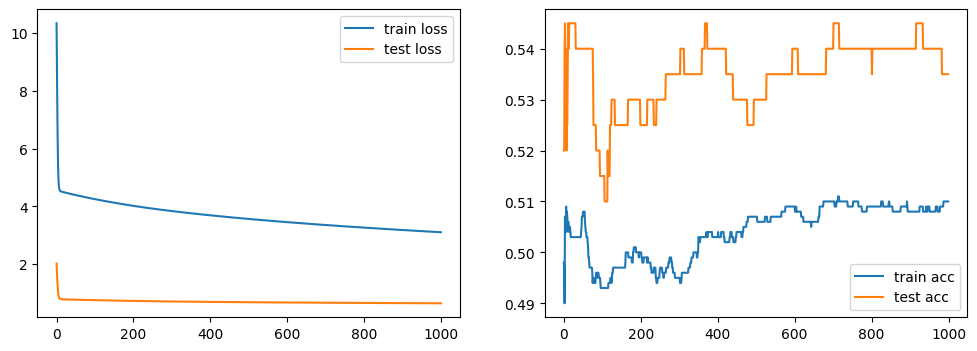

In [134]:
neuron.evaluation()